# Organoid morphometrics — hydraulic diameter distributions

Brightfield iHBO segmentation output (`organoid_morphometrics.xlsx`, sheet `objects`).

Everything is grouped by **constructor** (column C) and **condition** (column D),
both read from the sheet. The four conditions are `D2`, `D5`, `D8C`, `D8FT` —
note that these are conditions, not simply days: `D8C` and `D8FT` are two
different conditions at the same timepoint.

Plotting lives in reusable helpers (`hist_grid`, `violin_plot`, `save_fig`) so
other metrics (`area_um2`, `perimeter_um`) and other plot types can be added
without touching the loading code.

> **Do not convert `constructor` / `condition` to `pd.Categorical`.** See the
> note in section 2 — with seaborn 0.13.2 it silently misplaces data across
> facets. Section 6 verifies every panel against the numbers.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------------------------------------------------------- paths
# This notebook lives in .../Analysis/Plotting/
NB_DIR    = Path.cwd()
ANALYSIS  = NB_DIR.parent
XLSX      = ANALYSIS / "organoid_morphometrics.xlsx"
FIG_DIR   = NB_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

print("workbook:", XLSX, "| exists:", XLSX.exists())
print("seaborn:", sns.__version__)

workbook: /home/claude/run/Analysis/organoid_morphometrics.xlsx | exists: True
seaborn: 0.13.2


In [2]:
# ---------------------------------------------------------------- config
# Grouping variables, both read from the sheet:
#   constructor -> column C     condition -> column D
GROUP_COLS = ["constructor", "condition"]

# Level order for each grouping variable:
#   None            -> every level found in the column, sorted alphabetically
#   ["A", "B", ...] -> these levels in this order; any *other* level found in
#                      the column is appended and reported, never dropped.
CONSTRUCTOR_ORDER_PREF = None      # -> KT, VB, VV
CONDITION_ORDER_PREF   = None      # -> D2, D5, D8C, D8FT
CONSTRUCTOR_RENAME = {"VV": "Operator 1", "VB": "Operator 2", "KT": "Operator 3"}

# Display labels — panel titles and tick labels. Anything not listed is shown
# exactly as it appears in the sheet.
CONDITION_LABEL   = {"D8FT": "D8 FT"}
CONSTRUCTOR_LABEL = {}

# Categorical palette (colour-blind validated for these three hues together).
# Keyed by NAME, so each constructor keeps its colour whatever the order is.
PALETTE = {"Operator 1": "#2b4ece",   # blue
           "Operator 2": "#68cde9",   # orange
           "Operator 3": "#3885dd"}   # aqua

BINWIDTH = 2.0        # um  -- histogram bar width
METRIC   = "hydraulic_diameter_um"

# Size filter, applied once at load time, so every plot, table and test uses it.
# MIN_DIAMETER_UM           -> minimum for every condition (None = no filter)
# MIN_DIAMETER_BY_CONDITION -> condition-specific minimum; replaces the global
#                              one for the conditions listed here
MIN_DIAMETER_UM = 10.0
MIN_DIAMETER_BY_CONDITION = {}   # e.g. {"D8C": 20.0, "D8FT": 20.0}


def min_diameter_for(condition, default=None):
    """Size threshold (um) applied to `condition`."""
    default = MIN_DIAMETER_UM if default is None else default
    return MIN_DIAMETER_BY_CONDITION.get(condition, default)


# Stamped onto every figure so a saved PNG/SVG always states its own filter.
if MIN_DIAMETER_UM:
    FILTER_NOTE = f"objects < {MIN_DIAMETER_UM:g} µm excluded"
    _by_thr = {}
    for _c, _t in MIN_DIAMETER_BY_CONDITION.items():
        _by_thr.setdefault(_t, []).append(CONDITION_LABEL.get(_c, _c))
    if _by_thr:
        FILTER_NOTE += " (" + "; ".join(f"< {t:g} µm for {', '.join(c)}"
                                        for t, c in _by_thr.items()) + ")"
else:
    FILTER_NOTE = "no size filter"

In [3]:
# ---------------------------------------------------------------- style
# "ticks" has no gridlines; everything below keeps axes recessive.
sns.set_theme(context="paper", style="ticks")
mpl.rcParams.update({
    "figure.dpi":        110,
    "savefig.dpi":       300,
    "savefig.bbox":      "tight",
    "axes.grid":         False,      # no gridlines anywhere
    "axes.edgecolor":    "#52514e",
    "axes.linewidth":    0.8,
    "axes.labelcolor":   "#0b0b0b",
    "axes.titlesize":    10,
    "axes.labelsize":    10,
    "xtick.color":       "#52514e",
    "ytick.color":       "#52514e",
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "font.family":       "sans-serif",
    "font.sans-serif":   ["DejaVu Sans", "Arial", "Helvetica"],
    "svg.fonttype":      "none",     # keeps text editable in Illustrator
    "pdf.fonttype":      42,
})

## 2. Load data

### Why the grouping columns stay as plain strings

`constructor` and `condition` are deliberately **not** converted to
`pd.Categorical`. In seaborn 0.13.2, a categorical dtype whose category order
differs from the order the rows appear in the file makes `displot` and
`violinplot` assign data to the wrong facet / wrong violin while labelling them
with the requested order — silently.

This sheet triggers exactly that: the first data row is `VB` / `D8C`, so the
appearance order is `VB, KT, VV` and `D8C, D2, D5, D8FT`, neither of which
matches the plotting order. Ordering is therefore passed explicitly via
`order` / `row_order` / `col_order` / `hue_order` on plain string columns,
which is correct. Section 6 re-checks every panel against `groupby` numbers.

In [4]:
def infer_levels(df, column, preferred=None):
    """Levels actually present in `column`, in plotting order.

    Levels come from the data, so nothing in the sheet can be missed. If
    `preferred` is given it fixes the order of the levels it names; any level
    found in the column but absent from `preferred` is appended and reported
    rather than silently dropped.
    """
    present = list(pd.unique(df[column].dropna()))
    if not preferred:
        return sorted(present)
    ordered = [v for v in preferred if v in present]
    extra   = [v for v in present if v not in preferred]
    if extra:
        print(f"  ! {column}: level(s) {extra} found in the sheet but not in "
              f"the preferred order — appended at the end")
    missing = [v for v in preferred if v not in present]
    if missing:
        print(f"  ! {column}: preferred level(s) {missing} not present in the sheet")
    return ordered + extra


def load_objects(path=XLSX, min_diameter=MIN_DIAMETER_UM,
                 constructor_order=None, condition_order=None):
    """Per-object morphometrics.

    Returns (df, constructor_levels, condition_levels). The levels are read
    from columns C and D of the `objects` sheet. The grouping columns are left
    as plain strings on purpose — see the note above.
    """
    df   = pd.read_excel(path, sheet_name="objects")
    n_in = len(df)

    for col in GROUP_COLS:
        df[col] = df[col].astype(str).str.strip()
    df["constructor"] = df["constructor"].replace(CONSTRUCTOR_RENAME)

    ctors = infer_levels(df, "constructor",
                         CONSTRUCTOR_ORDER_PREF if constructor_order is None
                         else constructor_order)
    conds = infer_levels(df, "condition",
                         CONDITION_ORDER_PREF if condition_order is None
                         else condition_order)

    # every row must fall into a known level of BOTH grouping variables
    unknown = df[~df["constructor"].isin(ctors) | ~df["condition"].isin(conds)]
    assert unknown.empty, f"{len(unknown)} rows have an unrecognised group label"

    print(f"constructor levels (column C): {ctors}")
    print(f"condition   levels (column D): {conds}")
    print(f"rows read: {n_in} -> rows kept: {len(df)}")

    if min_diameter is not None:
        n0  = len(df)
        thr = df["condition"].map(lambda c: min_diameter_for(c, min_diameter))
        df  = df[df[METRIC] >= thr]
        for cond in conds:
            print(f"size filter {cond}: >= {min_diameter_for(cond, min_diameter):g} um")
        print(f"dropped {n0 - len(df)} of {n0} objects")

    return df.reset_index(drop=True), ctors, conds


objects, CONSTRUCTOR_ORDER, CONDITION_ORDER = load_objects()
objects.head()

constructor levels (column C): ['Operator 1', 'Operator 2', 'Operator 3']
condition   levels (column D): ['D2', 'D5', 'D8C', 'D8FT']
rows read: 3764 -> rows kept: 3764
size filter D2: >= 10 um
size filter D5: >= 10 um
size filter D8C: >= 10 um
size filter D8FT: >= 10 um
dropped 235 of 3764 objects


,file_name,fileset,constructor,condition,replicate,object_id,area_um2,perimeter_um,hydraulic_diameter_um,area_px,perimeter_px,pixel_size_um
0,EDF_sigma-50_VB-D8C-0001,Fileset_511447,Operator 2,D8C,1,1,212.805,54.733,15.552,787,105.255,0.52
1,EDF_sigma-50_VB-D8C-0001,Fileset_511447,Operator 2,D8C,1,2,613.267,94.133,26.060,2268,181.024,0.52
2,EDF_sigma-50_VB-D8C-0001,Fileset_511447,Operator 2,D8C,1,3,2884.627,218.416,52.828,10668,420.032,0.52
3,EDF_sigma-50_VB-D8C-0001,Fileset_511447,Operator 2,D8C,1,4,3783.978,234.521,64.540,13994,451.002,0.52
4,EDF_sigma-50_VB-D8C-0001,Fileset_511447,Operator 2,D8C,1,5,872.310,109.056,31.995,3226,209.723,0.52


In [5]:
def group_summary(df, metric=METRIC):
    """Per constructor x condition summary, grouped on BOTH keys."""
    s = (df.groupby(GROUP_COLS)[metric]
           .agg(n="size", mean="mean", median="median", std="std",
                q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75),
                min="min", max="max")
           .round(2))
    # present in plotting order
    idx = pd.MultiIndex.from_product([CONSTRUCTOR_ORDER, CONDITION_ORDER],
                                     names=GROUP_COLS)
    return s.reindex(idx)


counts = (objects.groupby(GROUP_COLS).size().unstack("constructor")
                 .reindex(index=CONDITION_ORDER, columns=CONSTRUCTOR_ORDER))
print("objects per condition x constructor  (total %d)" % len(objects))
display(counts)
display(group_summary(objects))

objects per condition x constructor  (total 3529)


constructor,Operator 1,Operator 2,Operator 3
condition,,,
D2,498,149,126
D5,568,485,307
D8C,217,305,483
D8FT,106,77,208


n   mean  median    std     q1     q3    min    max
constructor condition                                                       
Operator 1  D2         498  19.65   19.72   3.23  17.63  21.31  10.24  35.47
            D5         568  23.11   20.05   9.35  15.97  28.85  10.25  59.86
            D8C        217  33.05   24.04  20.13  17.02  48.10  10.02  87.42
            D8FT       106  36.95   29.21  21.85  16.05  55.75  10.42  88.35
Operator 2  D2         149  22.13   22.32   4.37  19.46  24.92  12.25  36.20
            D5         485  29.22   27.98  11.56  18.94  39.34  11.13  60.33
            D8C        305  32.40   25.42  17.97  17.21  47.35  10.94  89.31
            D8FT        77  53.06   53.07  17.92  44.69  65.39  11.71  95.55
Operator 3  D2         126  18.99   18.82   3.33  17.17  20.23  10.61  30.82
            D5         307  24.05   21.06   9.39  16.35  31.14  10.08  49.61
            D8C        483  27.20   18.79  17.99  15.04  34.84  10.05  90.50
            D8FT       208  34.59   25.77  19.92  18.18  48.75  10.04  95.02

## 3. Plot helpers

Generic enough to reuse for `area_um2`, `perimeter_um`, or other plot types.

In [6]:
def bin_edges(values, binwidth=BINWIDTH, start=0.0):
    """Bin edges of exactly `binwidth`, spanning `values`, anchored at `start`."""
    hi = float(np.nanmax(values))
    n  = int(np.ceil((hi - start) / binwidth)) + 1
    return start + np.arange(n + 1) * binwidth


def tidy_axes(ax):
    """No gridlines, no top/right spines, ticks pointing out."""
    ax.grid(False)
    sns.despine(ax=ax, top=True, right=True)
    ax.tick_params(direction="out", length=3, width=0.8)
    return ax


def presentation_style(ax, font_bump=2, ink="black", axis_lw=1.8, tick_len=5):
    """Bump every text element, force black ink, thicken the axis lines.

    Applied to a single axes after plotting, so rcParams stay untouched and
    every other figure keeps the smaller paper style. Sweeps the title, both
    axis labels, both sets of tick labels, any annotations added with
    ax.text (the "n =" row), and the legend if there is one.
    """
    texts = ([ax.title, ax.xaxis.label, ax.yaxis.label]
             + ax.get_xticklabels() + ax.get_yticklabels()
             + list(ax.texts))
    leg = ax.get_legend()
    if leg is not None:
        texts += list(leg.get_texts()) + ([leg.get_title()] if leg.get_title() else [])

    for t in texts:
        t.set_fontsize(t.get_fontsize() + font_bump)
        t.set_color(ink)

    for spine in ax.spines.values():
        spine.set_linewidth(axis_lw)
        spine.set_color(ink)

    ax.tick_params(width=axis_lw, length=tick_len, colors=ink)
    return ax


def save_fig(fig, name, formats=("png", "svg")):
    """Write `name.<ext>` into ./figures for each requested format."""
    paths = []
    for ext in formats:
        p = FIG_DIR / f"{name}.{ext}"
        fig.savefig(p, format=ext)
        paths.append(p)
    print("saved:", *[p.name for p in paths])
    return paths

In [7]:
def hist_grid(df,
              metric=METRIC,
              binwidth=BINWIDTH,
              row="condition", col="constructor",
              row_order=None, col_order=None,
              palette=PALETTE,
              stat="probability", common_norm=False,
              sharex=True, sharey=True,
              xlim=None,
              annotate_n=True,
              height=1.9, aspect=1.7,
              xlabel=None):
    """Grid of histograms: one row per condition, one column per constructor.

    Bars are exactly `binwidth` wide on a single shared set of bin edges, so
    bars line up across every panel.

    stat="probability" with common_norm=False normalises each panel by its own
    object count, i.e. the bars of one constructor x condition sum to 1.
    """
    row_order = row_order or CONDITION_ORDER
    col_order = col_order or CONSTRUCTOR_ORDER
    edges = bin_edges(df[metric], binwidth)

    g = sns.displot(
        data=df, x=metric,
        row=row, col=col, row_order=row_order, col_order=col_order,
        hue=col, hue_order=col_order, palette=palette, legend=False,
        kind="hist", bins=edges, stat=stat, common_norm=common_norm,
        element="bars", edgecolor="white", linewidth=0.4,
        height=height, aspect=aspect,
        facet_kws=dict(sharex=sharex, sharey=sharey, despine=True,
                       margin_titles=False),
    )

    g.set_titles("")   # drop seaborn's default "row = x | col = y" titles

    for (cond, ctor), ax in g.axes_dict.items():
        tidy_axes(ax)
        ax.set_title(f"{CONSTRUCTOR_LABEL.get(ctor, ctor)} · "
                     f"{CONDITION_LABEL.get(cond, cond)}",
                     loc="left", fontsize=10, fontweight="semibold",
                     color="#0b0b0b", pad=4)
        if annotate_n:
            n = int(((df[row] == cond) & (df[col] == ctor)).sum())
            ax.text(0.98, 0.92, f"n = {n}", transform=ax.transAxes,
                    ha="right", va="top", fontsize=8, color="#52514e")
        if xlim:
            ax.set_xlim(*xlim)

    ylabels = {"count": "Count", "probability": "Fraction of total",
               "density": "Density", "percent": "Percent of total"}
    g.set_axis_labels(xlabel or "Hydraulic diameter (µm)",
                      ylabels.get(stat, stat.capitalize()))
    g.figure.subplots_adjust(hspace=0.6, wspace=0.16, top=0.93)
    return g

## 4. Hydraulic diameter histograms — 2 µm bins

y-axis is **fraction of total**: each panel is divided by the number of organoids
analysed for that constructor x condition, so every panel's bars sum to 1.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


saved: hydraulic_diameter_hist_grid.png hydraulic_diameter_hist_grid.svg


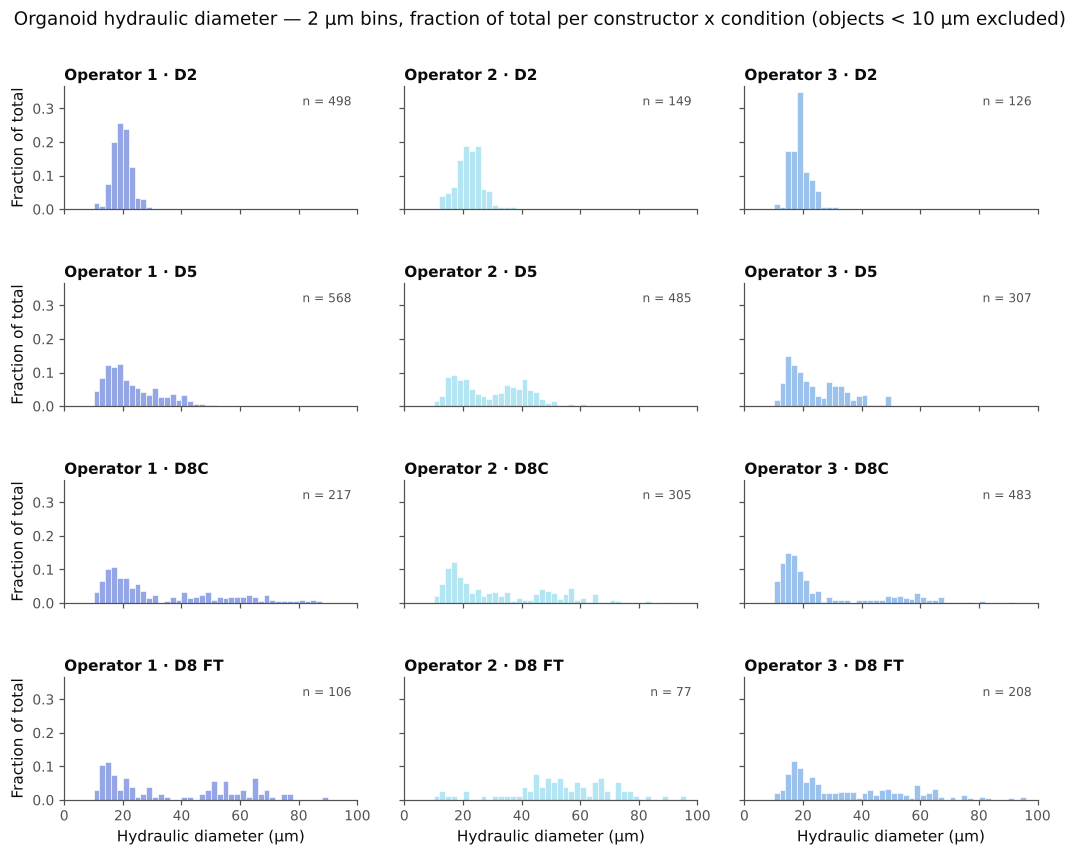

In [8]:
g = hist_grid(objects, metric=METRIC, binwidth=BINWIDTH,
              stat="probability", common_norm=False, xlim=(0, 100))
g.figure.suptitle("Organoid hydraulic diameter — 2 µm bins, fraction of total "
                  f"per constructor x condition ({FILTER_NOTE})",
                  x=0.02, ha="left", y=1.02, fontsize=12, color="#0b0b0b")
save_fig(g.figure, "hydraulic_diameter_hist_grid")
plt.show()

### Same grid as raw counts

Kept for reference — same bins, y-axis in objects rather than fraction.

saved: hydraulic_diameter_hist_grid_count.png hydraulic_diameter_hist_grid_count.svg


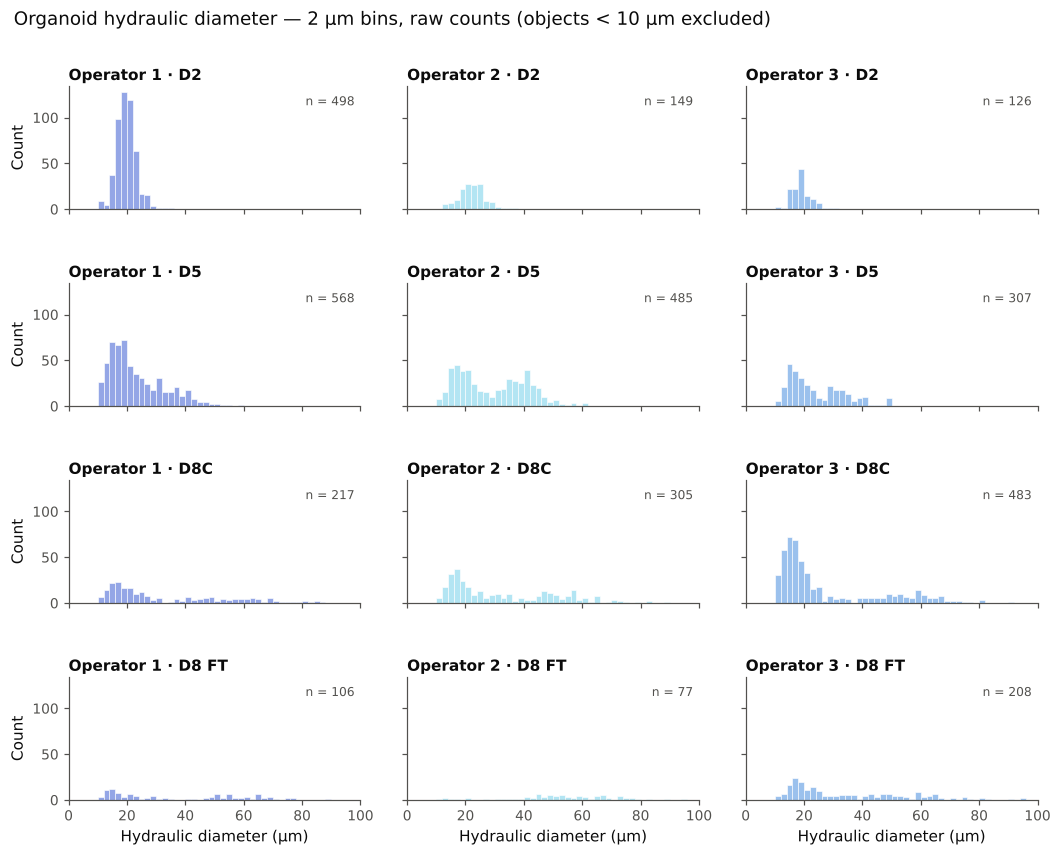

In [9]:
g = hist_grid(objects, metric=METRIC, binwidth=BINWIDTH,
              stat="count", xlim=(0, 100))
g.figure.suptitle(f"Organoid hydraulic diameter — 2 µm bins, raw counts ({FILTER_NOTE})",
                  x=0.02, ha="left", y=1.02, fontsize=12, color="#0b0b0b")
save_fig(g.figure, "hydraulic_diameter_hist_grid_count")
plt.show()

## 5. Violin plot

One panel, conditions on x, constructors as hue. A violin has to keep the
measured variable on y, so the "fraction of total" lives in the **width**: with
`width_by_n=True` each violin is scaled horizontally by
`n_group / n_largest_group`.

| `violin_plot(...)` | what width means |
|---|---|
| `width_by_n=True` *(default)* | width ∝ n — fraction of the largest group |
| `width_by_n=False, density_norm="width"` | every violin equally wide — pure shape |
| `width_by_n=False, density_norm="count"` | seaborn's own scaling: **area** ∝ n |

`cut=0` stops the kernel density extending past the observed range.

In [10]:
def _group_centres(df, x_order, hue_order, x, hue, dodge_width=0.8):
    """{violin centre on the x-axis: n objects in that violin}."""
    step = dodge_width / len(hue_order)
    return {round(i + (j - (len(hue_order) - 1) / 2) * step, 6):
            int(((df[x] == xv) & (df[hue] == hv)).sum())
            for i, xv in enumerate(x_order)
            for j, hv in enumerate(hue_order)}


def scale_violin_widths(ax, centres):
    """Squeeze each violin horizontally by n_group / n_largest_group.

    Called after seaborn has drawn equal-width violins, so the resulting width
    is literally the group's fraction of the largest group. Both the filled
    bodies and the inner quartile lines are rescaled about each violin's centre.
    """
    n_max = max(centres.values())
    keys  = np.array(sorted(centres))

    def nearest(c):
        k = keys[np.argmin(np.abs(keys - c))]
        return k, centres[k] / n_max

    for coll in ax.collections:                       # violin bodies
        for path in coll.get_paths():
            v = path.vertices
            centre, f = nearest((v[:, 0].min() + v[:, 0].max()) / 2)
            v[:, 0] = centre + (v[:, 0] - centre) * f

    for line in ax.lines:                             # inner quartile lines
        xd = np.asarray(line.get_xdata(), dtype=float)
        if xd.size == 0:
            continue
        centre, f = nearest((xd.min() + xd.max()) / 2)
        line.set_xdata(centre + (xd - centre) * f)
    return ax


def violin_plot(df,
                metric=METRIC,
                x="condition", hue="constructor",
                x_order=None, hue_order=None,
                palette=PALETTE,
                width_by_n=True,
                density_norm="width", common_norm=True,
                inner="quartile", cut=0,
                annotate_n=True,
                figsize=(6.4, 4),
                ylabel=None, ylim=None):
    """Violins of `metric`, grouped on x with `hue` dodged inside each group."""
    x_order   = x_order   or CONDITION_ORDER
    hue_order = hue_order or CONSTRUCTOR_ORDER

    fig, ax = plt.subplots(figsize=figsize)
    sns.violinplot(
        data=df, x=x, y=metric, hue=hue,
        order=x_order, hue_order=hue_order, palette=palette,
        density_norm="width" if width_by_n else density_norm,
        common_norm=common_norm,
        inner=inner, cut=cut, linewidth=1, linecolor="white",
        saturation=1.0,   # seaborn desaturates fills to 0.75 by default; keep
                          # the exact PALETTE hexes so violins match the histograms
        ax=ax,
    )

    centres = _group_centres(df, x_order, hue_order, x, hue)
    if width_by_n:
        scale_violin_widths(ax, centres)

    tidy_axes(ax)
    ax.set_xticks(range(len(x_order)))
    ax.set_xticklabels([CONDITION_LABEL.get(v, v) for v in x_order])
    ax.tick_params(axis="x", pad=6)
    # labelpad clears the "n =" row printed under the ticks
    ax.set_xlabel("Condition", labelpad=25 if annotate_n else 6, fontsize = 12)
    ax.set_ylabel(ylabel or "Hydraulic diameter (µm)", fontsize = 12)
    ax.set_ylim(ylim or (0, None))

    leg = ax.legend(title="", frameon=False, loc="upper left", fontsize = 12,
                    bbox_to_anchor=(1.01, 1.0), handlelength=1.0)
    for t in leg.get_texts():
        t.set_color("#0b0b0b")

    if annotate_n:
        for pos, n in centres.items():
            ax.text(pos, -0.115, str(n), transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=9, color="#52514e")
        ax.text(-0.012, -0.115, "n =", transform=ax.transAxes,
                ha="right", va="top", fontsize=9, color="#52514e")

    return fig, ax

saved: hydraulic_diameter_violin.png hydraulic_diameter_violin.svg


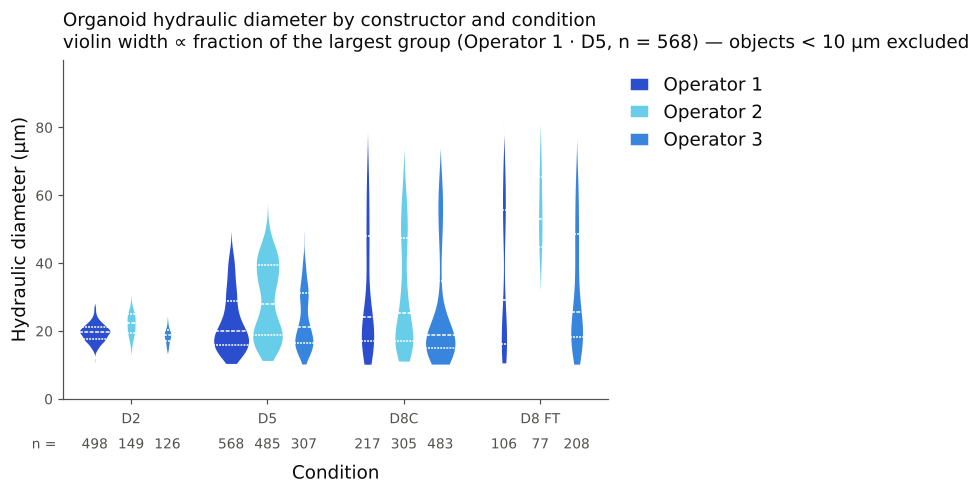

In [11]:
fig, ax = violin_plot(objects, metric=METRIC, width_by_n=True)

_sz  = objects.groupby(GROUP_COLS).size()
_big = _sz.idxmax()
ax.set_title("Organoid hydraulic diameter by constructor and condition\n"
             f"violin width \u221d fraction of the largest group "
             f"({_big[0]} \u00b7 {CONDITION_LABEL.get(_big[1], _big[1])}, "
             f"n = {int(_sz.max())}) — {FILTER_NOTE}",
             loc="left", fontsize=12, color="#0b0b0b", pad=8)
save_fig(fig, "hydraulic_diameter_violin")
plt.show()

### Equal-width variant

Every violin scaled to the same width, so distribution **shape** is compared with
group size taken out of it — at n = 19 the KT / D8 FT violin above is only 3% the
width of the largest group and its shape is impossible to read.

saved: hydraulic_diameter_violin_equalwidth.png hydraulic_diameter_violin_equalwidth.svg


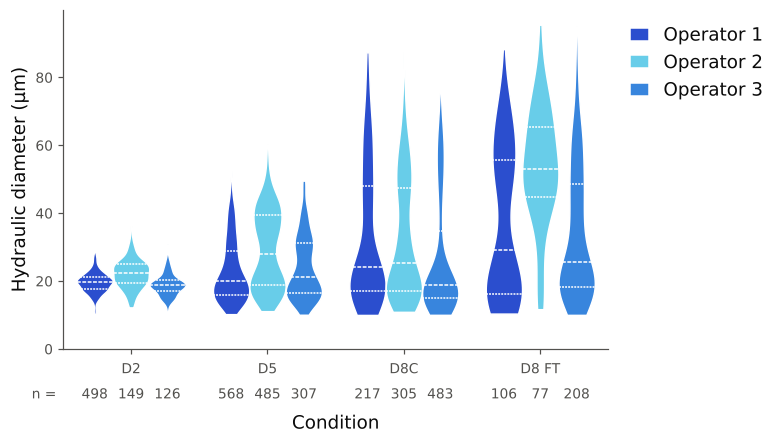

In [12]:
fig, ax = violin_plot(objects, metric=METRIC,
                      width_by_n=False, density_norm="width")
#ax.set_title("Organoid hydraulic diameter by constructor and condition\n"
#             f"all violins scaled to equal width — {FILTER_NOTE}",
#             loc="left", fontsize=12, color="#0b0b0b", pad=8)
save_fig(fig, "hydraulic_diameter_violin_equalwidth")
plt.show()

### All constructors pooled — one violin per condition

Every organoid from VV, VB and KT combined, split only by condition.

Because the three constructors contribute very unequally within a condition
(see the composition table printed below), each pooled violin is weighted
toward whichever constructor supplied the most objects — worth keeping in mind
before reading a pooled shape as "the" behaviour of that condition.

In [13]:
def violin_pooled(df,
                  metric=METRIC,
                  x="condition", x_order=None,
                  color="#2a78d6",
                  width_by_n=True, density_norm="width",
                  inner="quartile", cut=0,
                  annotate_n=True,
                  figsize=(7.6, 4.6),
                  xlabel="Condition", ylabel=None, ylim=None):
    """One violin per level of `x`, pooling every constructor together.

    Single series, so no legend — the x tick labels carry the identity.
    """
    x_order = x_order or CONDITION_ORDER

    fig, ax = plt.subplots(figsize=figsize)
    sns.violinplot(
        data=df, x=x, y=metric, order=x_order, color=color,
        density_norm="width" if width_by_n else density_norm,
        inner=inner, cut=cut, linewidth=0.8, linecolor="white",
        saturation=1.0, ax=ax,
    )

    centres = {float(i): int((df[x] == v).sum()) for i, v in enumerate(x_order)}
    if width_by_n:
        scale_violin_widths(ax, centres)

    tidy_axes(ax)
    ax.set_xticks(range(len(x_order)))
    ax.set_xticklabels([CONDITION_LABEL.get(v, v) for v in x_order])
    ax.tick_params(axis="x", pad=6)
    ax.set_xlabel(xlabel, labelpad=22 if annotate_n else 6)
    ax.set_ylabel(ylabel or "Hydraulic diameter (µm)")
    ax.set_ylim(ylim or (0, None))

    if annotate_n:
        for pos, n in centres.items():
            ax.text(pos, -0.115, str(n), transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=8, color="#52514e")
        ax.text(-0.012, -0.115, "n =", transform=ax.transAxes,
                ha="right", va="top", fontsize=8, color="#52514e")

    return fig, ax


# what each pooled violin is actually made of
composition = (objects.groupby(["condition", "constructor"]).size()
                      .unstack("constructor")
                      .reindex(index=CONDITION_ORDER, columns=CONSTRUCTOR_ORDER))
composition["total"] = composition.sum(axis=1)
print("objects contributing to each pooled violin:")
display(composition)
print("constructor share within each condition (%):")
display((composition[CONSTRUCTOR_ORDER]
         .div(composition["total"], axis=0) * 100).round(1))

objects contributing to each pooled violin:


constructor,Operator 1,Operator 2,Operator 3,total
condition,,,,
D2,498,149,126,773
D5,568,485,307,1360
D8C,217,305,483,1005
D8FT,106,77,208,391


constructor share within each condition (%):


constructor,Operator 1,Operator 2,Operator 3
condition,,,
D2,64.4,19.3,16.3
D5,41.8,35.7,22.6
D8C,21.6,30.3,48.1
D8FT,27.1,19.7,53.2


saved: hydraulic_diameter_violin_pooled.png hydraulic_diameter_violin_pooled.svg


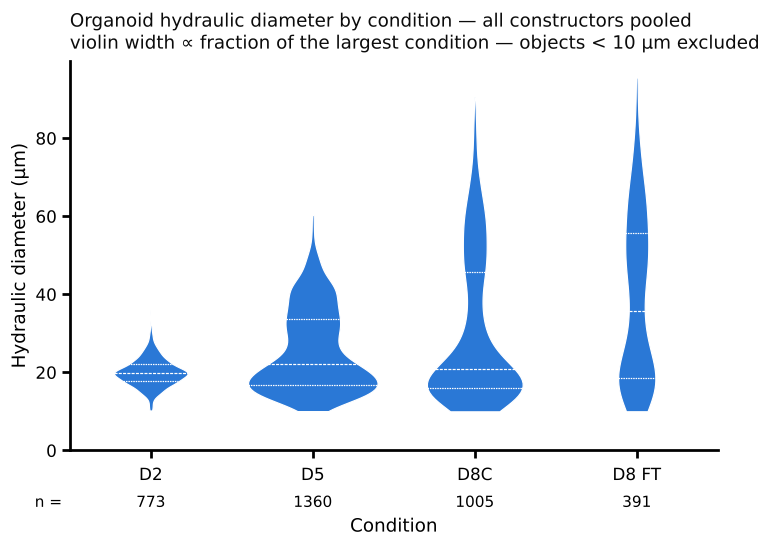

In [14]:
fig, ax = violin_pooled(objects, metric=METRIC, width_by_n=True)
ax.set_title("Organoid hydraulic diameter by condition — all constructors pooled\n"
             f"violin width \u221d fraction of the largest condition — {FILTER_NOTE}",
             loc="left", fontsize=12, color="#0b0b0b", pad=8)

# same larger black text / thicker axes as the equal-width version below
presentation_style(ax, font_bump=2, ink="black", axis_lw=1.8)

save_fig(fig, "hydraulic_diameter_violin_pooled")
plt.show()

## 6. Verification

Checks that the artists actually drawn hold the data their labels claim, by
re-deriving every panel from `groupby` and comparing. Run this after any change
to the plotting code — it is what catches a facet/label mismatch.

In [15]:
def verify_hist_grid(g, df, metric=METRIC, binwidth=BINWIDTH,
                     stat="probability", tol=1e-9):
    """Compare every panel's bar heights with its group's own histogram."""
    edges = bin_edges(df[metric], binwidth)
    rows  = []
    for (cond, ctor), ax in g.axes_dict.items():
        bars = sorted(ax.patches, key=lambda p: p.get_x())
        h    = np.array([p.get_height() for p in bars])[:len(edges) - 1]
        s    = df[(df["condition"] == cond) & (df["constructor"] == ctor)][metric]
        e, _ = np.histogram(s, bins=edges)
        exp  = e / e.sum() if stat == "probability" else e.astype(float)
        rows.append({"constructor": ctor, "condition": cond, "n": len(s),
                     "max_abs_diff": float(np.abs(exp - h).max())})
    res = pd.DataFrame(rows)
    ok  = bool((res.max_abs_diff < tol).all())
    print(f"histogram panels holding their labelled data: "
          f"{int((res.max_abs_diff < tol).sum())}/{len(res)}  ->  "
          f"{'PASS' if ok else 'FAIL'}")
    return res


def verify_violins(ax, df, metric=METRIC, x="condition", hue="constructor",
                   x_order=None, hue_order=None, tol=0.5):
    """With cut=0 a violin spans exactly its group's min..max — check that."""
    x_order   = x_order   or CONDITION_ORDER
    hue_order = hue_order or CONSTRUCTOR_ORDER
    step, rows = 0.8 / len(hue_order), []
    for coll in ax.collections:
        v  = coll.get_paths()[0].vertices
        cx = (v[:, 0].min() + v[:, 0].max()) / 2
        i  = min(max(int(round(cx)), 0), len(x_order) - 1)
        j  = min(max(int(round((cx - i) / step + (len(hue_order) - 1) / 2)), 0),
                 len(hue_order) - 1)
        cond, ctor = x_order[i], hue_order[j]
        s = df[(df[x] == cond) & (df[hue] == ctor)][metric]
        rows.append({"constructor": ctor, "condition": cond, "n": len(s),
                     "d_min": abs(v[:, 1].min() - s.min()),
                     "d_max": abs(v[:, 1].max() - s.max())})
    res = pd.DataFrame(rows)
    good = (res.d_min < tol) & (res.d_max < tol)
    print(f"violins holding their labelled data: {int(good.sum())}/{len(res)}"
          f"  ->  {'PASS' if bool(good.all()) else 'FAIL'}")
    return res


def verify_violins_pooled(ax, df, metric=METRIC, x="condition",
                          x_order=None, tol=0.5):
    """Same check for the pooled (single-series) violins."""
    x_order, rows = x_order or CONDITION_ORDER, []
    for coll in ax.collections:
        v = coll.get_paths()[0].vertices
        i = min(max(int(round((v[:, 0].min() + v[:, 0].max()) / 2)), 0),
                len(x_order) - 1)
        s = df[df[x] == x_order[i]][metric]
        rows.append({"condition": x_order[i], "n": len(s),
                     "d_min": abs(v[:, 1].min() - s.min()),
                     "d_max": abs(v[:, 1].max() - s.max())})
    res  = pd.DataFrame(rows)
    good = (res.d_min < tol) & (res.d_max < tol)
    print(f"pooled violins holding their labelled data: "
          f"{int(good.sum())}/{len(res)}  ->  "
          f"{'PASS' if bool(good.all()) else 'FAIL'}")
    return res

In [16]:
# 1. every histogram panel matches its own group
_g   = hist_grid(objects, stat="probability", common_norm=False)
_hv  = verify_hist_grid(_g, objects)
plt.close(_g.figure)

# 2. every panel's fractions sum to 1
_sums = (objects.groupby(GROUP_COLS)[METRIC]
                .apply(lambda s: np.histogram(s, bins=bin_edges(objects[METRIC]))[0].sum()
                                 / len(s)))
print("every panel sums to 1.0:", bool(np.allclose(_sums.values, 1.0)))

# 3. every violin matches its own group
_f, _a = violin_plot(objects, width_by_n=True)
_vv    = verify_violins(_a, objects)
plt.close(_f)

# 3b. every pooled violin matches its condition, and pooling loses nobody
_f2, _a2 = violin_pooled(objects, width_by_n=True)
_pv      = verify_violins_pooled(_a2, objects)
plt.close(_f2)
print("pooled n per condition sums to the full dataset:",
      int(_pv.n.sum()) == len(objects), f"({int(_pv.n.sum())} of {len(objects)})")

# 4. cross-check against the workbook's own summary sheet.
#    That sheet is UNFILTERED, so compare it to an unfiltered reload, then
#    separately confirm the filter removed exactly what it should have.
_raw, _, _ = load_objects(min_diameter=None)
_ref  = pd.read_excel(XLSX, sheet_name="summary_by_condition")
_ref["constructor"] = _ref["constructor"].replace(CONSTRUCTOR_RENAME)
_mine = _raw.groupby(GROUP_COLS)[METRIC].agg(["size", "median"]).reset_index()
_chk  = _ref.merge(_mine, on=GROUP_COLS)
print("unfiltered counts match summary_by_condition sheet:",
      bool((_chk.n_objects == _chk["size"]).all()))
print("unfiltered medians match summary_by_condition sheet:",
      bool((_chk.hydraulic_diameter_um_median - _chk["median"]).abs().max() < 0.01))

if MIN_DIAMETER_UM:
    _thr_raw = _raw["condition"].map(min_diameter_for)
    _expected_drop = int((_raw[METRIC] < _thr_raw).sum())
    print("filter removed exactly the objects below each condition's threshold:",
          len(_raw) - len(objects) == _expected_drop,
          f"({_expected_drop} dropped, {len(objects)} kept)")
    print("no object below the threshold survives:",
          bool((objects[METRIC] >= objects["condition"].map(min_diameter_for)).all()))
    display(pd.concat([
        _raw.groupby(GROUP_COLS).size().rename("before"),
        objects.groupby(GROUP_COLS).size().rename("after"),
    ], axis=1).assign(dropped=lambda d: d.before - d.after))

display(_hv)

histogram panels holding their labelled data: 12/12  ->  PASS
every panel sums to 1.0: True
violins holding their labelled data: 12/12  ->  PASS


pooled violins holding their labelled data: 4/4  ->  PASS
pooled n per condition sums to the full dataset: True (3529 of 3529)


constructor levels (column C): ['Operator 1', 'Operator 2', 'Operator 3']
condition   levels (column D): ['D2', 'D5', 'D8C', 'D8FT']
rows read: 3764 -> rows kept: 3764
unfiltered counts match summary_by_condition sheet: False
unfiltered medians match summary_by_condition sheet: False
filter removed exactly the objects below each condition's threshold: True (235 dropped, 3529 kept)
no object below the threshold survives: True


before  after  dropped
constructor condition                        
Operator 1  D2            508    498       10
            D5            600    568       32
            D8C           235    217       18
            D8FT          110    106        4
Operator 2  D2            151    149        2
            D5            510    485       25
            D8C           334    305       29
            D8FT           82     77        5
Operator 3  D2            127    126        1
            D5            313    307        6
            D8C           541    483       58
            D8FT          253    208       45

,constructor,condition,n,max_abs_diff
0,Operator 1,D2,498,0.0
1,Operator 2,D2,149,0.0
2,Operator 3,D2,126,0.0
3,Operator 1,D5,568,0.0
4,Operator 2,D5,485,0.0
5,Operator 3,D5,307,0.0
6,Operator 1,D8C,217,0.0
7,Operator 2,D8C,305,0.0
8,Operator 3,D8C,483,0.0
9,Operator 1,D8FT,106,0.0


## 7. Scratch space — further plots

The helpers take any numeric column, so e.g.

```python
g = hist_grid(objects, metric="area_um2", binwidth=100, xlabel="Area (µm²)")
save_fig(g.figure, "area_hist_grid")
verify_hist_grid(g, objects, metric="area_um2", binwidth=100)
```

Or a different form entirely:

```python
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=objects, x="condition", y=METRIC, hue="constructor",
            order=CONDITION_ORDER, hue_order=CONSTRUCTOR_ORDER,
            palette=PALETTE, saturation=1.0, fliersize=2, linewidth=0.8, ax=ax)
tidy_axes(ax)
ax.set(xlabel="Condition", ylabel="Hydraulic diameter (µm)")
save_fig(fig, "hydraulic_diameter_box")
```

Always pass `order=` / `hue_order=` explicitly and leave the grouping columns as
plain strings — see the note in section 2.

saved: hydraulic_diameter_violin_pooled_equal_width.png hydraulic_diameter_violin_pooled_equal_width.svg


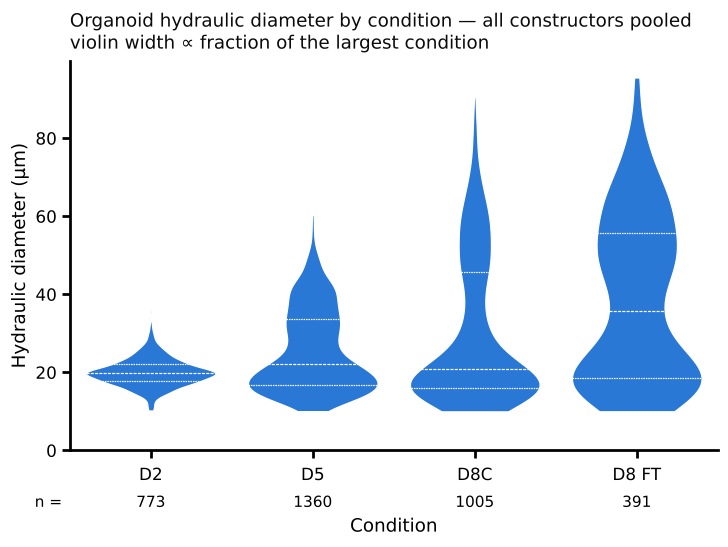

In [17]:
# your plots here
fig, ax = violin_pooled(objects, metric=METRIC, width_by_n=False, density_norm = "width")
ax.set_title("Organoid hydraulic diameter by condition — all constructors pooled\n"
             "violin width ∝ fraction of the largest condition",
             loc="left", fontsize=12, color="#0b0b0b", pad=8)

# ---- presentation styling, local to THIS figure only -------------------
# (rcParams are left untouched, so every other figure keeps the paper style)
FONT_BUMP = 2          # points added to every text element
INK       = "black"    # all text and axis lines
AXIS_LW   = 1.8        # axis / tick line width

for txt in ([ax.title, ax.xaxis.label, ax.yaxis.label]
            + ax.get_xticklabels() + ax.get_yticklabels()
            + list(ax.texts)):                      # includes the "n =" row
    txt.set_fontsize(txt.get_fontsize() + FONT_BUMP)
    txt.set_color(INK)

for spine in ax.spines.values():
    spine.set_linewidth(AXIS_LW)
    spine.set_color(INK)

ax.tick_params(width=AXIS_LW, length=5, colors=INK)

save_fig(fig, "hydraulic_diameter_violin_pooled_equal_width")
plt.show()


## 8. Statistics — operator-to-operator comparison within each condition

**Question:** within one condition, do the three operators produce organoids of different size?

**Unit of replication = image, not organoid.** All organoids in one image come from the same well and culture, so they are not independent. Testing ~500 objects as 500 samples (pseudoreplication) turns tiny differences into p < 10⁻¹⁰ — the `p_object_level` column is shown only to make that visible and is never used for the stars.

| `STAT_METHOD` | what is tested | when to use |
|---|---|---|
| `"image"` *(default)* | median diameter per image → Kruskal–Wallis, then pairwise Mann–Whitney U, Holm-corrected within condition | simple, assumption-light, easy to report |
| `"mixed"` | linear mixed model `log(d) ~ operator + (1 \| image)`, pairwise Wald contrasts, Holm-corrected | uses every organoid while respecting the nesting; more power; needs `statsmodels` |

Stars: ns ≥ 0.05, * < 0.05, ** < 0.01, *** < 0.001, **** < 0.0001 (Holm-adjusted). † marks a comparison involving a group with fewer than `MIN_IMAGES_FLAG` images (D8 FT · Operator 3 has only 2) — interpret with caution.

`ANNOT_STYLE = "stars" | "p" | "both"`; `SHOW_NS = False` hides non-significant brackets. The full table is written to `figures/stats_operator_comparison_<method>.csv`.

In [18]:
# ---------------------------------------------------------------- statistics
# Operator-to-operator comparison WITHIN each condition.
#
# Experimental unit = IMAGE (one image = one replicate in this sheet), not the
# individual organoid: organoids in the same image/well share culture history,
# so treating ~500 objects as 500 independent samples inflates n and makes
# almost any difference "significant" (see the p_object_level column in the
# table below — kept for reference only, never used for the stars).
#
# STAT_METHOD
#   "image"  (default) per-image median -> Kruskal-Wallis across operators,
#            then pairwise Mann-Whitney U, Holm-corrected within each condition.
#   "mixed"  linear mixed model on log(diameter), operator = fixed effect,
#            image = random intercept; pairwise Wald contrasts, Holm-corrected.
#            Uses every object while still respecting the nesting. Needs
#            statsmodels (pip install statsmodels).
#
# ANNOT_STYLE   "stars" | "p" | "both"
# SHOW_NS       False hides non-significant brackets.
from itertools import combinations
from scipy import stats

STAT_METHOD    = "image"
STAT_METRIC    = METRIC
ANNOT_STYLE    = "p"
SHOW_NS        = True
ALPHA          = 0.05
MIN_IMAGES_FLAG = 3      # groups with fewer images than this get a † in the table


def p_to_stars(p):
    if p < 1e-4: return "****"
    if p < 1e-3: return "***"
    if p < 1e-2: return "**"
    if p < ALPHA: return "*"
    return "ns"

def p_to_NA_or_p(p):
    if p < ALPHA: return p
    return "ns"


def p_label(p, style=ANNOT_STYLE):
    if p >= ALPHA:                  # not significant -> "ns", whatever the style
        return "ns"
    if p < 1e-4:   ptxt = "p < 0.0001"
    elif p < 1e-3: ptxt = f"p = {p:.4f}"
    elif p < 0.01: ptxt = f"p = {p:.3f}"
    else:          ptxt = f"p = {p:.2f}"
    if style == "p":
        return ptxt
    if style == "both":
        return f"{p_to_stars(p)}\n{ptxt}"
    return p_to_stars(p)


def holm(pvals):
    """Holm–Bonferroni adjusted p-values (same order as input)."""
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


def image_medians(df, metric=STAT_METRIC):
    """One value per image: the median organoid size in that image."""
    return (df.groupby(GROUP_COLS + ["file_name"])[metric]
              .agg(value="median", n_objects="size").reset_index())


def _mixed_pairwise(sub, metric, ops):
    """Pairwise operator contrasts from log(metric) ~ operator + (1 | image)."""
    import statsmodels.formula.api as smf
    sub = sub.assign(_log=np.log(sub[metric]))
    ref = ops[0]
    formula = f"_log ~ C(constructor, Treatment(reference='{ref}'))"
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = smf.mixedlm(formula, sub, groups=sub["file_name"]).fit(reml=True)
    fe   = fit.fe_params
    cov  = fit.cov_params().loc[fe.index, fe.index].values
    names = list(fe.index)

    def coef_idx(op):
        if op == ref:
            return None
        return next(i for i, n in enumerate(names) if f"[T.{op}]" in n)

    out = {}
    for a, b in combinations(ops, 2):
        L = np.zeros(len(names))
        ia, ib = coef_idx(a), coef_idx(b)
        if ib is not None: L[ib] += 1
        if ia is not None: L[ia] -= 1
        est, se = L @ fe.values, np.sqrt(L @ cov @ L)
        out[(a, b)] = float(2 * stats.norm.sf(abs(est / se)))
    # omnibus: Wald chi-square that all operator coefficients are 0
    k = [i for i, n in enumerate(names) if "[T." in n]
    b, V = fe.values[k], cov[np.ix_(k, k)]
    omni = float(stats.chi2.sf(b @ np.linalg.solve(V, b), df=len(k)))
    return out, omni


def compare_operators(df, metric=STAT_METRIC, method=STAT_METHOD,
                      cond_order=None, op_order=None):
    """Pairwise operator comparisons within each condition.

    Returns (pairwise_table, omnibus_table).
    """
    cond_order = cond_order or CONDITION_ORDER
    op_order   = op_order   or CONSTRUCTOR_ORDER
    img = image_medians(df, metric)
    pair_rows, omni_rows = [], []

    for cond in cond_order:
        sub_obj = df[df["condition"] == cond]
        sub_img = img[img["condition"] == cond]
        ops = [o for o in op_order if (sub_img["constructor"] == o).any()]
        g_img = {o: sub_img.loc[sub_img["constructor"] == o, "value"].values for o in ops}
        g_obj = {o: sub_obj.loc[sub_obj["constructor"] == o, metric].values for o in ops}

        if method == "image":
            omni_p = stats.kruskal(*g_img.values()).pvalue
            omni_name = "Kruskal-Wallis (image medians)"
            raw = {(a, b): stats.mannwhitneyu(g_img[a], g_img[b],
                                              alternative="two-sided").pvalue
                   for a, b in combinations(ops, 2)}
            test_name = "Mann-Whitney U (image medians)"
        elif method == "mixed":
            raw, omni_p = _mixed_pairwise(sub_obj, metric, ops)
            omni_name = "Wald, LMM log(d) ~ operator + (1|image)"
            test_name = "LMM contrast"
        else:
            raise ValueError("STAT_METHOD must be 'image' or 'mixed'")

        omni_rows.append({"condition": cond, "test": omni_name,
                          "n_images": {o: len(g_img[o]) for o in ops},
                          "p": omni_p})

        pairs = list(raw)
        adj = holm([raw[p] for p in pairs])
        for (a, b), p_adj in zip(pairs, adj):
            flag = "†" if min(len(g_img[a]), len(g_img[b])) < MIN_IMAGES_FLAG else ""
            pair_rows.append({
                "condition": cond, "group1": a, "group2": b,
                "n_img1": len(g_img[a]), "n_img2": len(g_img[b]),
                "median1": np.median(g_img[a]), "median2": np.median(g_img[b]),
                "ratio_2_vs_1": np.median(g_img[b]) / np.median(g_img[a]),
                "test": test_name,
                "p_raw": raw[(a, b)], "p_holm": p_adj,
                #"label": p_to_stars(p_adj) + flag,
                "label": str(p_to_NA_or_p(p_adj)) + flag,
                "p_object_level": stats.mannwhitneyu(g_obj[a], g_obj[b],
                                                     alternative="two-sided").pvalue,
            })

    pw = pd.DataFrame(pair_rows)
    om = pd.DataFrame(omni_rows)
    return pw, om


def add_stat_brackets(ax, df, pw, metric=STAT_METRIC,
                      x="condition", hue="constructor",
                      x_order=None, hue_order=None,
                      style=ANNOT_STYLE, show_ns=SHOW_NS,
                      step_frac=0.07, fontsize=9, lw=1.0, color="black",
                      p_col="p_holm", ymax_by_cond=None):
    """Draw comparison brackets above the dodged violins of each condition."""
    x_order   = x_order   or CONDITION_ORDER
    hue_order = hue_order or CONSTRUCTOR_ORDER
    step = 0.8 / len(hue_order)

    def xpos(cond, op):
        i, j = x_order.index(cond), hue_order.index(op)
        return i + (j - (len(hue_order) - 1) / 2) * step

    y0, y1 = ax.get_ylim()
    span = (df[metric].max() - y0)
    # taller steps when the label is a p-value or two lines
    dy   = step_frac * span * {"stars": 1.0, "p": 1.3, "both": 2.0}.get(style, 1.0)
    top_used = y1

    for cond in x_order:
        rows = pw[pw["condition"] == cond]
        rows = rows[rows[p_col].notna()]
        if not show_ns:
            rows = rows[rows[p_col] < ALPHA]
        if rows.empty:
            continue
        # adjacent pairs first (lowest), widest pair on top
        rows = rows.assign(_w=rows.apply(lambda r: abs(hue_order.index(r.group2)
                                                       - hue_order.index(r.group1)),
                                         axis=1)).sort_values(["_w", "group1"])
        top  = (ymax_by_cond or {}).get(cond, df.loc[df[x] == cond, metric].max())
        base = top + 0.6 * dy
        for k, r in enumerate(rows.itertuples()):
            xa, xb = xpos(cond, r.group1), xpos(cond, r.group2)
            y  = base + k * dy
            ax.plot([xa, xa, xb, xb], [y - dy * 0.25, y, y, y - dy * 0.25],
                    lw=lw, color=color, clip_on=False)
            p_ = getattr(r, p_col)
            txt = p_label(p_, style)
            if r.label.endswith("†"):
                txt += "†"
            is_ns = p_ >= ALPHA
            ax.text((xa + xb) / 2, y + (0.02 * dy if not is_ns or style != "stars" else 0.12 * dy),
                    txt, ha="center", va="bottom",
                    fontsize=fontsize - (1 if is_ns or style != "stars" else 0),
                    color=color, linespacing=0.9)
            top_used = max(top_used, y + dy)
    ax.set_ylim(y0, top_used)
    return ax


# ---------------------------------------------------------------- run
pairwise, omnibus = compare_operators(objects, method=STAT_METHOD)

print(f"Method: {STAT_METHOD}   metric: {STAT_METRIC}   ({FILTER_NOTE})")
print("Omnibus test per condition (do the operators differ at all?):")
display(omnibus.style.format({"p": "{:.4f}"}))

print("Pairwise, Holm-corrected within each condition "
      f"(† = a group with < {MIN_IMAGES_FLAG} images):")
display(pairwise.drop(columns="test").style.format({
    "median1": "{:.1f}", "median2": "{:.1f}", "ratio_2_vs_1": "{:.2f}",
    "p_raw": "{:.4f}", "p_holm": "{:.4f}", "p_object_level": "{:.2g}"}))

_csv = FIG_DIR / f"stats_operator_comparison_{STAT_METHOD}.csv"
pairwise.merge(omnibus[["condition", "p"]].rename(columns={"p": "p_omnibus"}),
               on="condition").to_csv(_csv, index=False)
print("saved:", _csv.name)

Method: image   metric: hydraulic_diameter_um   (objects < 10 µm excluded)
Omnibus test per condition (do the operators differ at all?):


,condition,test,n_images,p
0,D2,Kruskal-Wallis (image medians),"{'Operator 1': 6, 'Operator 2': 5, 'Operator 3': 5}",0.0220
1,D5,Kruskal-Wallis (image medians),"{'Operator 1': 6, 'Operator 2': 6, 'Operator 3': 7}",0.3818
2,D8C,Kruskal-Wallis (image medians),"{'Operator 1': 10, 'Operator 2': 6, 'Operator 3': 7}",0.2639
3,D8FT,Kruskal-Wallis (image medians),"{'Operator 1': 11, 'Operator 2': 12, 'Operator 3': 10}",0.0004


Pairwise, Holm-corrected within each condition († = a group with < 3 images):


,condition,group1,group2,n_img1,n_img2,median1,median2,ratio_2_vs_1,p_raw,p_holm,label,p_object_level
0,D2,Operator 1,Operator 2,6,5,19.8,21.7,1.10,0.0087,0.0260,0.025974025974025976,1.3e-11
1,D2,Operator 1,Operator 3,6,5,19.8,18.7,0.95,0.2468,0.2468,ns,0.006
2,D2,Operator 2,Operator 3,5,5,21.7,18.7,0.86,0.0556,0.1111,ns,6.5e-11
3,D5,Operator 1,Operator 2,6,6,20.6,27.5,1.34,0.2403,0.7208,ns,3.8e-18
4,D5,Operator 1,Operator 3,6,7,20.6,22.4,1.09,0.5338,0.8904,ns,0.14
5,D5,Operator 2,Operator 3,6,7,27.5,22.4,0.82,0.4452,0.8904,ns,3.1e-10
6,D8C,Operator 1,Operator 2,10,6,23.9,24.2,1.01,0.8749,0.8749,ns,0.94
7,D8C,Operator 1,Operator 3,10,7,23.9,19.1,0.80,0.1088,0.3264,ns,4.9e-06
8,D8C,Operator 2,Operator 3,6,7,24.2,19.1,0.79,0.3660,0.7319,ns,1.7e-07
9,D8FT,Operator 1,Operator 2,11,12,29.3,56.9,1.94,0.0006,0.0019,0.0019079260241524833,8.6e-06


saved: stats_operator_comparison_image.csv


saved: hydraulic_diameter_violin_equalwidth_stats_image.png hydraulic_diameter_violin_equalwidth_stats_image.svg


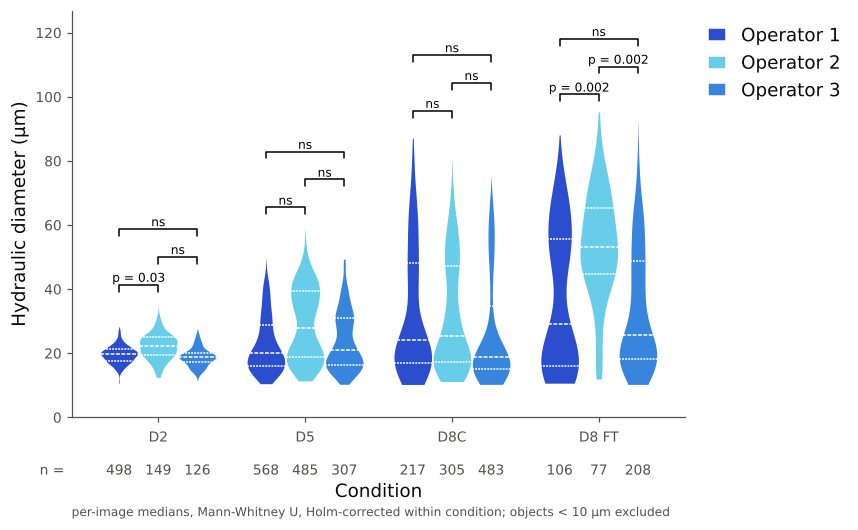

In [19]:
# ---------------------------------------------------------------- annotated violin
# Equal-width violins (shape comparable even at small n) with the operator
# comparisons from the cell above drawn as brackets inside each condition.
fig, ax = violin_plot(objects, metric=STAT_METRIC,
                      width_by_n=False, density_norm="width",
                      figsize=(7.2, 4.8))
add_stat_brackets(ax, objects, pairwise, metric=STAT_METRIC,
                  style=ANNOT_STYLE, show_ns=SHOW_NS)

_method_note = {
    "image": "per-image medians, Mann-Whitney U, Holm-corrected within condition",
    "mixed": "LMM log(d) ~ operator + (1|image), Holm-corrected within condition",
}[STAT_METHOD]
ax.text(0.0, -0.22, f"{_method_note}; {FILTER_NOTE}"
        + (f"; † < {MIN_IMAGES_FLAG} images" if pairwise.label.str.endswith("†").any() else ""),
        transform=ax.transAxes, ha="left", va="top", fontsize=8, color="#52514e")

save_fig(fig, f"hydraulic_diameter_violin_equalwidth_stats_{STAT_METHOD}")
plt.show()

## 9. Organoid population only — adaptive threshold per condition, two-way ANOVA

The size distribution is bimodal in most conditions: a large population of small 2–few-cell clusters, and a smaller population of larger structures that are the actual organoids. This section finds the split **automatically for each condition** and runs the statistics on the larger population only.

**How the threshold is found** (`THRESHOLD_MODE = "adaptive"`), separately for each condition, with all operators pooled so that every operator in a condition is cut at the same diameter:

1. Fit one Gaussian and a mixture of two Gaussians to log₁₀(diameter). Log scale because size distributions are right-skewed.
2. Call the condition **bimodal** only if the two-Gaussian fit is clearly better (ΔBIC > `BIC_MIN`) **and** the two peaks are well separated (Ashman's D > `ASHMAN_D_MIN`; D > 2 is the standard criterion for a clean two-population split).
3. **Bimodal** → threshold = the diameter where an object is equally likely to belong to either population (the valley between the two fitted peaks). Statistics use the objects above it.
   **Unimodal** (e.g. D2) → no threshold; statistics use every object.

`THRESHOLD_MODE = "fixed"` reverts to one cut-off (`LARGE_MIN_UM`) for all conditions. The diagnostic figure below shows the fits and thresholds; check it before trusting the numbers.

**Read-outs, per image (each image = one replicate):**

| read-out | question it answers |
|---|---|
| **Organoid size**: mean diameter of the larger population (all objects for unimodal conditions) | once an organoid forms, is it the same size whatever the operator? |
| **% organoids**: larger population as % of all objects in the image (bimodal conditions only) | does each operator get the same proportion of structures to grow into organoids? |

**Statistics:** two-way ANOVA (*condition* × *operator*, with interaction, Type III sums of squares as in Prism) followed by operator comparisons within each condition (`POSTHOC`): `"tukey"` (Tukey's multiple comparisons, default) or `"ttest"` (unpaired Student's t-test, Holm-corrected). † marks a group with fewer than `MIN_IMAGES_FLAG` images.

> In the size ANOVA, D2 (all objects) and the other conditions (larger population only) are different selections, so the **condition** row compares unlike things. The **operator** comparisons within each condition, which are the question here, are unaffected.

In [20]:
# ---------------------------------------------------------------- organoid population: threshold + stats
THRESHOLD_MODE    = "adaptive"  # "adaptive" (per condition, from the data) | "fixed"
LARGE_MIN_UM      = 40.0        # cut-off used when THRESHOLD_MODE = "fixed"
ASHMAN_D_MIN      = 2.0         # peak separation needed to call a condition bimodal
BIC_MIN           = 10.0        # how much better the 2-Gaussian fit must be (ΔBIC)
POSTHOC           = "tukey"     # "tukey" | "ttest"
LARGE_ANNOT_STYLE = "p"     # "stars" | "p" | "both"
LARGE_SHOW_NS     = True


def _fit_two_gaussians(x, n_iter=1000, tol=1e-10):
    """1-D two-component Gaussian mixture by EM. Returns weights, means, sds, log-lik
    with components ordered small -> large."""
    x = np.asarray(x, float)
    w, mu = np.array([0.5, 0.5]), np.quantile(x, [0.25, 0.75])
    sd = np.array([x.std() / 2] * 2)
    ll_old = -np.inf
    for _ in range(n_iter):
        p   = w * stats.norm.pdf(x[:, None], mu, sd)
        tot = p.sum(axis=1)
        ll  = float(np.log(tot).sum())
        r   = p / tot[:, None]
        nk  = r.sum(axis=0)
        w, mu = nk / len(x), (r * x[:, None]).sum(axis=0) / nk
        sd  = np.maximum(np.sqrt((r * (x[:, None] - mu) ** 2).sum(axis=0) / nk), 1e-3)
        if ll - ll_old < tol:
            break
        ll_old = ll
    o = np.argsort(mu)
    return w[o], mu[o], sd[o], ll


def detect_threshold(values):
    """Decide whether `values` (µm) are bimodal; if so return the valley diameter."""
    x  = np.log10(np.asarray(values, float))
    n  = len(x)
    ll1 = float(stats.norm.logpdf(x, x.mean(), x.std()).sum())
    w, mu, sd, ll2 = _fit_two_gaussians(x)
    d_bic   = (-2 * ll1 + 2 * np.log(n)) - (-2 * ll2 + 5 * np.log(n))
    ashman  = np.sqrt(2) * abs(mu[1] - mu[0]) / np.sqrt(sd[0] ** 2 + sd[1] ** 2)
    bimodal = bool(d_bic > BIC_MIN and ashman > ASHMAN_D_MIN)
    thr = np.nan
    if bimodal:   # equal-posterior point between the two means
        g    = np.linspace(mu[0], mu[1], 4000)
        diff = (w[0] * stats.norm.pdf(g, mu[0], sd[0])
                - w[1] * stats.norm.pdf(g, mu[1], sd[1]))
        thr  = float(10 ** g[np.argmax(diff < 0)])
    return {"n_objects": n, "bimodal": bimodal, "threshold_um": thr,
            "delta_BIC": d_bic, "ashman_D": ashman,
            "small_peak_um": 10 ** mu[0], "large_peak_um": 10 ** mu[1],
            "large_weight": w[1],
            "_fit": (w, mu, sd)}


def condition_thresholds(df, metric=METRIC, mode=THRESHOLD_MODE):
    """{condition: threshold in µm, or None = use every object}, plus a report table."""
    rows, thr = [], {}
    for cond in CONDITION_ORDER:
        v = df.loc[df["condition"] == cond, metric]
        r = detect_threshold(v)
        if mode == "fixed":
            r["bimodal"], r["threshold_um"] = True, LARGE_MIN_UM
        elif mode != "adaptive":
            raise ValueError("THRESHOLD_MODE must be 'adaptive' or 'fixed'")
        thr[cond] = r["threshold_um"] if r["bimodal"] else None
        r["frac_selected"] = (float((v >= thr[cond]).mean()) if thr[cond] else 1.0)
        rows.append({"condition": cond, **r})
    return thr, pd.DataFrame(rows).set_index("condition")


def per_image_large(df, thresholds, metric=METRIC):
    """One row per image: n objects, n in the organoid population, % and mean size.

    Conditions with threshold None keep every object (mean over all objects) and
    get no % value, since 'organoid population' is not defined there.
    """
    keys = GROUP_COLS + ["file_name"]
    thr  = df["condition"].map(lambda c: thresholds.get(c) or -np.inf)
    sel  = df[df[metric] >= thr]
    out  = (df.groupby(keys)[metric].agg(n_objects="size")
              .join(sel.groupby(keys)[metric].agg(n_large="size", mean_large="mean"))
              .reset_index())
    out["n_large"]   = out["n_large"].fillna(0).astype(int)
    out["pct_large"] = 100 * out["n_large"] / out["n_objects"]
    out.loc[out["condition"].map(lambda c: thresholds.get(c) is None), "pct_large"] = np.nan
    return out


def select_population(df, thresholds, metric=METRIC):
    """Objects in the organoid population (all objects for unimodal conditions)."""
    thr = df["condition"].map(lambda c: thresholds.get(c) or -np.inf)
    return df[df[metric] >= thr]


def _effect_code(values, levels):
    """Sum-to-zero (effect) coding: k-1 columns, last level coded -1."""
    X = np.zeros((len(values), len(levels) - 1))
    v = np.asarray(values)
    for j, lv in enumerate(levels[:-1]):
        X[v == lv, j] = 1.0
    X[v == levels[-1], :] = -1.0
    return X


def two_way_anova(data, value, a="condition", b="constructor",
                  a_order=None, b_order=None):
    """Two-way ANOVA with interaction, Type III SS (unequal n allowed).

    Returns (anova_table, MS_residual, df_residual).
    """
    d  = data.dropna(subset=[value])
    la = [l for l in (a_order or CONDITION_ORDER)   if (d[a] == l).any()]
    lb = [l for l in (b_order or CONSTRUCTOR_ORDER) if (d[b] == l).any()]
    A, B = _effect_code(d[a], la), _effect_code(d[b], lb)
    AB = np.column_stack([A[:, i] * B[:, j]
                          for i in range(A.shape[1]) for j in range(B.shape[1])])
    y, one = d[value].to_numpy(float), np.ones((len(d), 1))

    def fit(blocks):
        X = np.column_stack([one] + blocks)
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        r = y - X @ beta
        return float(r @ r), int(np.linalg.matrix_rank(X))

    blocks = {"A": A, "B": B, "AB": AB}
    rss_full, rank_full = fit(list(blocks.values()))
    df_err = len(y) - rank_full
    mse    = rss_full / df_err
    rows = []
    for label, key in [(a, "A"), (b, "B"), (f"{a} × {b}", "AB")]:
        rss_red, rank_red = fit([blk for k, blk in blocks.items() if k != key])
        ss, dfn = rss_red - rss_full, rank_full - rank_red
        F = (ss / dfn) / mse
        rows.append({"source": label, "SS": ss, "df": dfn, "MS": ss / dfn,
                     "F": F, "p": stats.f.sf(F, dfn, df_err)})
    rows.append({"source": "Residual", "SS": rss_full, "df": df_err, "MS": mse,
                 "F": np.nan, "p": np.nan})
    tab = pd.DataFrame(rows)
    tab["significance"] = tab["p"].map(lambda p: "" if pd.isna(p) else p_to_stars(p))
    return tab, mse, df_err


def posthoc_within_condition(data, value, mse, df_err, method=POSTHOC,
                             cond_order=None, op_order=None):
    """Operator vs operator inside each condition (Tukey or Student's t)."""
    d = data.dropna(subset=[value])
    cond_order = [c for c in (cond_order or CONDITION_ORDER) if (d["condition"] == c).any()]
    op_order   = op_order or CONSTRUCTOR_ORDER
    rows = []
    for cond in cond_order:
        sub = d[d["condition"] == cond]
        g   = {o: sub.loc[sub["constructor"] == o, value].to_numpy(float)
               for o in op_order if (sub["constructor"] == o).any()}
        pairs, raw = list(combinations(g, 2)), []
        for a_, b_ in pairs:
            xa, xb = g[a_], g[b_]
            if method == "tukey":
                se = np.sqrt(mse / 2 * (1 / len(xa) + 1 / len(xb)))
                q  = abs(xa.mean() - xb.mean()) / se
                raw.append(float(stats.studentized_range.sf(q, len(g), df_err)))
            elif method == "ttest":
                raw.append(float(stats.ttest_ind(xa, xb, equal_var=True).pvalue)
                           if min(len(xa), len(xb)) >= 2 else np.nan)
            else:
                raise ValueError("POSTHOC must be 'tukey' or 'ttest'")
        if method == "ttest":
            ok  = [i for i, p in enumerate(raw) if not np.isnan(p)]
            adj = np.full(len(raw), np.nan)
            if ok:
                adj[ok] = holm([raw[i] for i in ok])
        else:
            adj = np.array(raw)          # Tukey p-values are already adjusted
        for (a_, b_), p_adj in zip(pairs, adj):
            xa, xb = g[a_], g[b_]
            flag = "†" if min(len(xa), len(xb)) < MIN_IMAGES_FLAG else ""
            rows.append({
                "condition": cond, "group1": a_, "group2": b_,
                "n_img1": len(xa), "n_img2": len(xb),
                "mean1": xa.mean(), "sd1": xa.std(ddof=1) if len(xa) > 1 else np.nan,
                "mean2": xb.mean(), "sd2": xb.std(ddof=1) if len(xb) > 1 else np.nan,
                "diff_2_minus_1": xb.mean() - xa.mean(),
                "test": "Tukey" if method == "tukey" else "Student's t (Holm)",
                "p_adj": p_adj,
                "label": ("n/a" if np.isnan(p_adj) else p_to_stars(p_adj)) + flag,
            })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- run
THRESHOLDS, threshold_report = condition_thresholds(objects)
print(f"Threshold mode: {THRESHOLD_MODE}   ({FILTER_NOTE})")
display(threshold_report.drop(columns="_fit").style.format({
    "threshold_um": "{:.1f}", "delta_BIC": "{:.1f}", "ashman_D": "{:.2f}",
    "small_peak_um": "{:.1f}", "large_peak_um": "{:.1f}",
    "large_weight": "{:.2f}", "frac_selected": "{:.2f}"}, na_rep="– (unimodal: all objects)"))

img_large = per_image_large(objects, THRESHOLDS)
_bimodal  = [c for c in CONDITION_ORDER if THRESHOLDS[c] is not None]

anova_size, mse_size, dfe_size = two_way_anova(img_large, "mean_large")
ph_size = posthoc_within_condition(img_large, "mean_large", mse_size, dfe_size)
_pct_in = img_large[img_large["condition"].isin(_bimodal)]
if len(_bimodal) >= 2:
    anova_pct, mse_pct, dfe_pct = two_way_anova(_pct_in, "pct_large", a_order=_bimodal)
    ph_pct = posthoc_within_condition(_pct_in, "pct_large", mse_pct, dfe_pct,
                                      cond_order=_bimodal)
else:
    anova_pct = ph_pct = None
    print("! fewer than 2 bimodal conditions — % organoids not analysed")

_fmt_anova = {"SS": "{:.1f}", "MS": "{:.1f}", "F": "{:.2f}", "p": "{:.4f}"}
_fmt_ph    = {"mean1": "{:.1f}", "sd1": "{:.1f}", "mean2": "{:.1f}", "sd2": "{:.1f}",
              "diff_2_minus_1": "{:.1f}", "p_adj": "{:.4f}"}

print(f"\nreplicate = image;  post-hoc = {POSTHOC}")
print("Images contributing to the size analysis, per condition x operator:")
display(img_large.dropna(subset=["mean_large"]).groupby(GROUP_COLS).size()
          .unstack("constructor").reindex(index=CONDITION_ORDER, columns=CONSTRUCTOR_ORDER)
          .fillna(0).astype(int))

print("\nA) ORGANOID SIZE (per-image mean diameter, µm) — two-way ANOVA")
display(anova_size.style.format(_fmt_anova, na_rep=""))
display(ph_size.style.format(_fmt_ph, na_rep="–"))

if anova_pct is not None:
    print(f"\nB) % ORGANOIDS per image (bimodal conditions: {', '.join(_bimodal)}) — two-way ANOVA")
    display(anova_pct.style.format(_fmt_anova, na_rep=""))
    display(ph_pct.style.format(_fmt_ph, na_rep="–"))

_tag = f"{THRESHOLD_MODE}_{POSTHOC}"
threshold_report.drop(columns="_fit").to_csv(FIG_DIR / f"organoid_thresholds_{THRESHOLD_MODE}.csv")
img_large.to_csv(FIG_DIR / f"organoids_per_image_{THRESHOLD_MODE}.csv", index=False)
pd.concat([anova_size.assign(readout="size")]
          + ([anova_pct.assign(readout="pct")] if anova_pct is not None else [])
          ).to_csv(FIG_DIR / f"organoids_anova_{THRESHOLD_MODE}.csv", index=False)
pd.concat([ph_size.assign(readout="size")]
          + ([ph_pct.assign(readout="pct")] if ph_pct is not None else [])
          ).to_csv(FIG_DIR / f"organoids_posthoc_{_tag}.csv", index=False)
print(f"saved: organoid_thresholds / organoids_per_image / organoids_anova / organoids_posthoc CSVs ({_tag})")

Threshold mode: adaptive   (objects < 10 µm excluded)


,n_objects,bimodal,threshold_um,delta_BIC,ashman_D,small_peak_um,large_peak_um,large_weight,frac_selected
condition,,,,,,,,,
D2,773,False,– (unimodal: all objects),11.0,0.16,19.3,19.9,0.66,1.00
D5,1360,True,26.7,231.4,3.34,17.8,36.2,0.39,0.39
D8C,1005,True,32.4,426.5,4.34,17.6,52.3,0.33,0.33
D8FT,391,True,32.6,137.3,4.08,18.7,54.7,0.53,0.53



replicate = image;  post-hoc = tukey
Images contributing to the size analysis, per condition x operator:


constructor,Operator 1,Operator 2,Operator 3
condition,,,
D2,6,5,5
D5,6,6,7
D8C,10,6,7
D8FT,11,12,9



A) ORGANOID SIZE (per-image mean diameter, µm) — two-way ANOVA


...

,condition,group1,group2,n_img1,n_img2,mean1,sd1,mean2,sd2,diff_2_minus_1,test,p_adj,label
0,D2,Operator 1,Operator 2,6,5,19.7,0.3,22.9,2.6,3.1,Tukey,0.6191,ns
1,D2,Operator 1,Operator 3,6,5,19.7,0.3,19.6,2.0,-0.2,Tukey,0.9987,ns
2,D2,Operator 2,Operator 3,5,5,22.9,2.6,19.6,2.0,-3.3,Tukey,0.6151,ns
3,D5,Operator 1,Operator 2,6,6,35.4,0.9,38.6,1.7,3.2,Tukey,0.5701,ns
4,D5,Operator 1,Operator 3,6,7,35.4,0.9,34.7,1.8,-0.7,Tukey,0.9710,ns
5,D5,Operator 2,Operator 3,6,7,38.6,1.7,34.7,1.8,-4.0,Tukey,0.4085,ns
6,D8C,Operator 1,Operator 2,10,6,56.5,3.6,52.1,1.5,-4.5,Tukey,0.2678,ns
7,D8C,Operator 1,Operator 3,10,7,56.5,3.6,55.6,3.2,-0.9,Tukey,0.9399,ns
8,D8C,Operator 2,Operator 3,6,7,52.1,1.5,55.6,3.2,3.6,Tukey,0.4844,ns
9,D8FT,Operator 1,Operator 2,11,12,58.0,5.0,63.5,11.3,5.5,Tukey,0.0540,ns



B) % ORGANOIDS per image (bimodal conditions: D5, D8C, D8FT) — two-way ANOVA


,source,SS,df,MS,F,p,significance
0,condition,8161.5,2,4080.8,14.21,0.0000,****
1,constructor,4416.4,2,2208.2,7.69,0.0010,***
2,condition × constructor,5147.7,4,1286.9,4.48,0.0029,**
3,Residual,18955.4,66,287.2,,,


,condition,group1,group2,n_img1,n_img2,mean1,sd1,mean2,sd2,diff_2_minus_1,test,p_adj,label
0,D5,Operator 1,Operator 2,6,6,34.0,15.1,48.4,10.6,14.4,Tukey,0.3127,ns
1,D5,Operator 1,Operator 3,6,7,34.0,15.1,41.1,13.4,7.1,Tukey,0.7349,ns
2,D5,Operator 2,Operator 3,6,7,48.4,10.6,41.1,13.4,-7.3,Tukey,0.7202,ns
3,D8C,Operator 1,Operator 2,10,6,40.2,13.1,36.7,9.7,-3.5,Tukey,0.9177,ns
4,D8C,Operator 1,Operator 3,10,7,40.2,13.1,29.6,14.6,-10.6,Tukey,0.4194,ns
5,D8C,Operator 2,Operator 3,6,7,36.7,9.7,29.6,14.6,-7.1,Tukey,0.7320,ns
6,D8FT,Operator 1,Operator 2,11,12,47.7,13.7,84.7,17.6,37.0,Tukey,0.0000,****
7,D8FT,Operator 1,Operator 3,11,10,47.7,13.7,44.3,29.1,-3.4,Tukey,0.8928,ns
8,D8FT,Operator 2,Operator 3,12,10,84.7,17.6,44.3,29.1,-40.4,Tukey,0.0000,****


saved: organoid_thresholds / organoids_per_image / organoids_anova / organoids_posthoc CSVs (adaptive_tukey)


saved: organoid_threshold_diagnostics_adaptive.png organoid_threshold_diagnostics_adaptive.svg


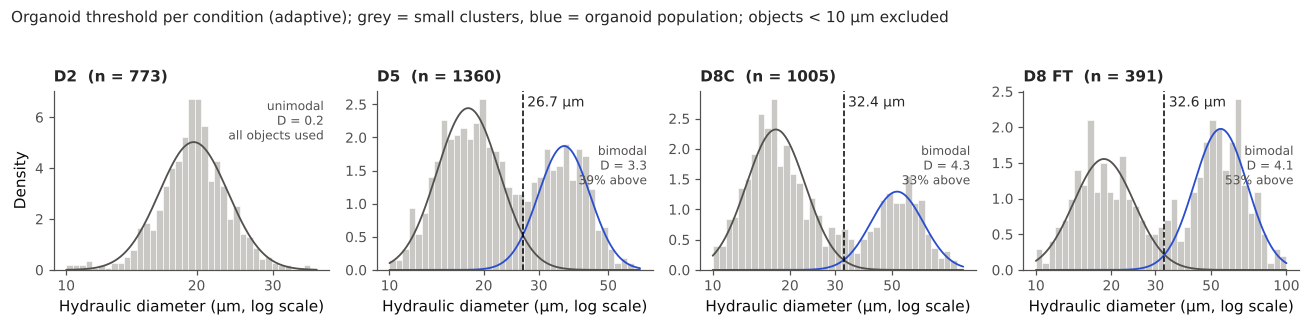

In [21]:
# ---------------------------------------------------------------- threshold diagnostics
# One panel per condition: histogram of log diameter (all operators pooled), the
# fitted Gaussians, and the threshold. Check this before trusting the statistics.
fig, axes = plt.subplots(1, len(CONDITION_ORDER), figsize=(3.0 * len(CONDITION_ORDER), 2.8),
                         sharey=False)
for ax, cond in zip(np.atleast_1d(axes), CONDITION_ORDER):
    v   = objects.loc[objects["condition"] == cond, METRIC].to_numpy()
    rep = threshold_report.loc[cond]
    lv  = np.log10(v)
    bins = np.linspace(np.log10(max(MIN_DIAMETER_UM or 1, 1)), np.log10(v.max()) + 0.02, 40)
    ax.hist(lv, bins=bins, density=True, color="#c9c8c4", edgecolor="white", linewidth=0.4)
    g = np.linspace(bins[0], bins[-1], 400)
    w, mu, sd = rep["_fit"]
    if rep["bimodal"] or THRESHOLD_MODE == "fixed":
        ax.plot(g, w[0] * stats.norm.pdf(g, mu[0], sd[0]), color="#52514e", lw=1.2)
        ax.plot(g, w[1] * stats.norm.pdf(g, mu[1], sd[1]), color="#2b4ece", lw=1.2)
        t = rep["threshold_um"]
        ax.axvline(np.log10(t), color="black", ls="--", lw=1)
        ax.text(np.log10(t), ax.get_ylim()[1] * 0.97, f" {t:.1f} µm", ha="left", va="top", fontsize=9)
        ax.text(0.98, 0.70, f"bimodal\nD = {rep['ashman_D']:.1f}\n{100 * rep['frac_selected']:.0f}% above",
                transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#52514e")
    else:
        ax.plot(g, stats.norm.pdf(g, lv.mean(), lv.std()), color="#52514e", lw=1.2)
        ax.text(0.98, 0.95, f"unimodal\nD = {rep['ashman_D']:.1f}\nall objects used",
                transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#52514e")
    ticks = [t for t in (10, 20, 30, 50, 100) if bins[0] <= np.log10(t) <= bins[-1]]
    ax.set_xticks(np.log10(ticks))
    ax.set_xticklabels([str(t) for t in ticks])
    ax.set_title(f"{CONDITION_LABEL.get(cond, cond)}  (n = {len(v)})", loc="left",
                 fontsize=10, fontweight="semibold")
    ax.set_xlabel("Hydraulic diameter (µm, log scale)")
    tidy_axes(ax)
np.atleast_1d(axes)[0].set_ylabel("Density")
fig.suptitle(f"Organoid threshold per condition ({THRESHOLD_MODE}); grey = small clusters, "
             f"blue = organoid population; {FILTER_NOTE}",
             x=0.01, ha="left", y=1.04, fontsize=10)
fig.tight_layout()
save_fig(fig, f"organoid_threshold_diagnostics_{THRESHOLD_MODE}")
plt.show()

saved: organoids_size_adaptive_tukey.png organoids_size_adaptive_tukey.svg


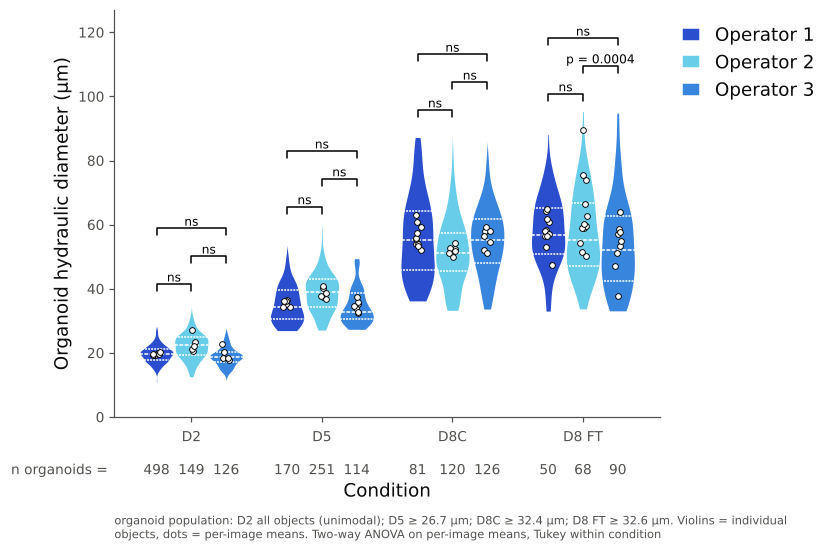

In [22]:
# ---------------------------------------------------------------- organoid population: figures
_conds_L = [c for c in CONDITION_ORDER if (img_large["condition"] == c).any()]
_step    = 0.8 / len(CONSTRUCTOR_ORDER)
_rng     = np.random.default_rng(0)          # fixed jitter -> identical figure every run


def _xpos(cond, op, x_order):
    return (x_order.index(cond)
            + (CONSTRUCTOR_ORDER.index(op) - (len(CONSTRUCTOR_ORDER) - 1) / 2) * _step)


def _overlay_image_points(ax, img, value, x_order):
    """One white dot per image (the replicate the test actually used)."""
    for cond in x_order:
        for op in CONSTRUCTOR_ORDER:
            v = img.loc[(img["condition"] == cond) & (img["constructor"] == op), value].dropna()
            if v.empty:
                continue
            x = _xpos(cond, op, x_order) + _rng.uniform(-0.03, 0.03, len(v))
            ax.scatter(x, v, s=14, facecolor="white", edgecolor="black",
                       linewidth=0.6, zorder=4)


# ---- A) organoid size ---------------------------------------------------------
_large_obj = select_population(objects, THRESHOLDS)
_conds_A   = [c for c in _conds_L if (_large_obj["condition"] == c).any()]

fig, ax = violin_plot(_large_obj, metric=METRIC, x_order=_conds_A,
                      width_by_n=False, density_norm="width", figsize=(6.4, 4.8))
_overlay_image_points(ax, img_large, "mean_large", _conds_A)
_ymax = {c: max(_large_obj.loc[_large_obj["condition"] == c, METRIC].max(),
                img_large.loc[img_large["condition"] == c, "mean_large"].max())
         for c in _conds_A}
add_stat_brackets(ax, _large_obj, ph_size, metric=METRIC, x_order=_conds_A,
                  style=LARGE_ANNOT_STYLE, show_ns=LARGE_SHOW_NS,
                  p_col="p_adj", ymax_by_cond=_ymax)
ax.set_ylabel("Organoid hydraulic diameter (µm)")
ax.text(-0.012, -0.115, "n organoids =", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color="#52514e")
for t in ax.texts:                       # drop violin_plot's own "n =" label
    if t.get_text() == "n =":
        t.set_visible(False)
ax.text(0.0, -0.24,
        "organoid population: " + "; ".join(
            f"{CONDITION_LABEL.get(c, c)} ≥ {THRESHOLDS[c]:.1f} µm" if THRESHOLDS[c] else
            f"{CONDITION_LABEL.get(c, c)} all objects (unimodal)" for c in _conds_A)
        + ". Violins = individual objects, dots = per-image means. "
        f"Two-way ANOVA on per-image means, {'Tukey' if POSTHOC == 'tukey' else 'Student’s t (Holm)'} "
        f"within condition" + (f"; † < {MIN_IMAGES_FLAG} images" if ph_size.label.str.endswith('†').any() else ""),
        transform=ax.transAxes, ha="left", va="top", fontsize=7.5, color="#52514e", wrap=True)
save_fig(fig, f"organoids_size_{THRESHOLD_MODE}_{POSTHOC}")
plt.show()

saved: organoids_percent_adaptive_tukey.png organoids_percent_adaptive_tukey.svg


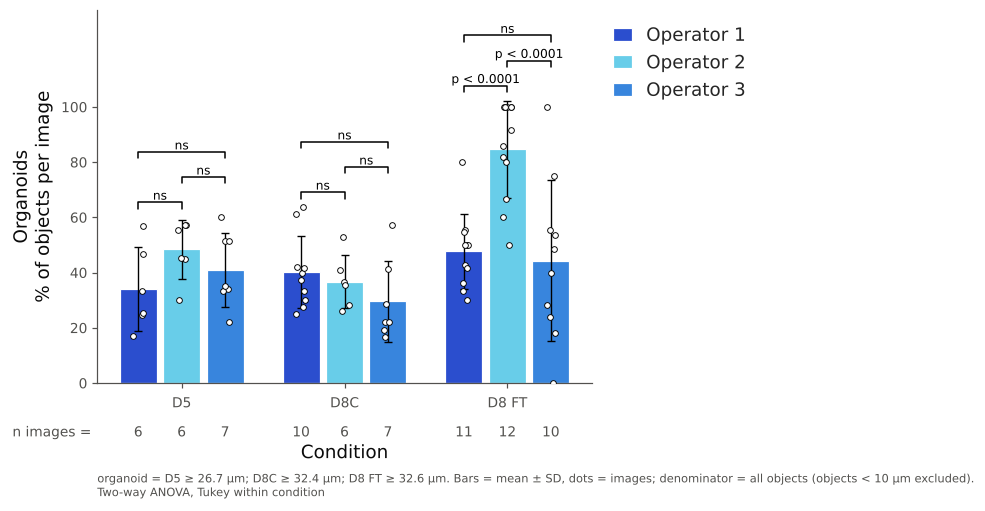

In [23]:
# ---- B) % organoids per image (bimodal conditions only) ---------------------
_conds_L = _bimodal
fig, ax = plt.subplots(figsize=(1.0 + 1.6 * len(_conds_L), 4.4))
for cond in _conds_L:
    for op in CONSTRUCTOR_ORDER:
        v = img_large.loc[(img_large["condition"] == cond)
                          & (img_large["constructor"] == op), "pct_large"]
        if v.empty:
            continue
        x  = _xpos(cond, op, _conds_L)
        sd = v.std(ddof=1) if len(v) > 1 else 0
        ax.bar(x, v.mean(), width=_step * 0.85, color=PALETTE[op], zorder=2,
               label=op if cond == _conds_L[0] else None)
        ax.errorbar(x, v.mean(), yerr=sd, color="black", capsize=2.5,
                    elinewidth=0.9, capthick=0.9, zorder=3)
        ax.text(x, -0.115, str(len(v)), transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=9, color="#52514e")
_overlay_image_points(ax, img_large, "pct_large", _conds_L)

_ymax = {}
for c in _conds_L:
    s = img_large[img_large["condition"] == c].groupby("constructor")["pct_large"]
    _ymax[c] = float(max(s.max().max(), (s.mean() + s.std().fillna(0)).max()))
ax.set_ylim(0, 100)
add_stat_brackets(ax, img_large, ph_pct, metric="pct_large", x_order=_conds_L,
                  style=LARGE_ANNOT_STYLE, show_ns=LARGE_SHOW_NS,
                  p_col="p_adj", ymax_by_cond=_ymax)

tidy_axes(ax)
ax.set_xticks(range(len(_conds_L)))
ax.set_xticklabels([CONDITION_LABEL.get(c, c) for c in _conds_L])
ax.tick_params(axis="x", pad=6)
ax.set_yticks(range(0, 101, 20))
ax.set_xlabel("Condition", labelpad=22, fontsize=12)
ax.set_ylabel("Organoids\n% of objects per image", fontsize=12)
ax.text(-0.012, -0.115, "n images =", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color="#52514e")
leg = ax.legend(title="", frameon=False, loc="upper left", fontsize=12,
                bbox_to_anchor=(1.01, 1.0), handlelength=1.0)
ax.text(0.0, -0.24,
        "organoid = " + "; ".join(f"{CONDITION_LABEL.get(c, c)} ≥ {THRESHOLDS[c]:.1f} µm" for c in _conds_L)
        + f". Bars = mean ± SD, dots = images; denominator = all objects ({FILTER_NOTE}).\n"
        f"Two-way ANOVA, {'Tukey' if POSTHOC == 'tukey' else 'Student’s t (Holm)'} within condition"
        + (f"; † < {MIN_IMAGES_FLAG} images" if ph_pct.label.str.endswith('†').any() else ""),
        transform=ax.transAxes, ha="left", va="top", fontsize=7.5, color="#52514e")
save_fig(fig, f"organoids_percent_{THRESHOLD_MODE}_{POSTHOC}")
plt.show()